##Part e

<>:32: SyntaxWarning: invalid escape sequence '\e'
<>:57: SyntaxWarning: invalid escape sequence '\e'
<>:80: SyntaxWarning: invalid escape sequence '\e'
<>:32: SyntaxWarning: invalid escape sequence '\e'
<>:57: SyntaxWarning: invalid escape sequence '\e'
<>:80: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_3653/589242255.py:32: SyntaxWarning: invalid escape sequence '\e'
  ax_1.plot(x_1, y_1, z_1, color='b', linewidth=2, label=f'$\epsilon < \epsilon_0$')
/tmp/ipykernel_3653/589242255.py:57: SyntaxWarning: invalid escape sequence '\e'
  ax_2.plot(x_2, y_2, z_2, color='b', linewidth=2, label=f'$\epsilon = \epsilon_0$')
/tmp/ipykernel_3653/589242255.py:80: SyntaxWarning: invalid escape sequence '\e'
  ax_3.plot(x_3, y_3, z_3, color='b', linewidth=2, label=f'$\epsilon > \epsilon_0$')


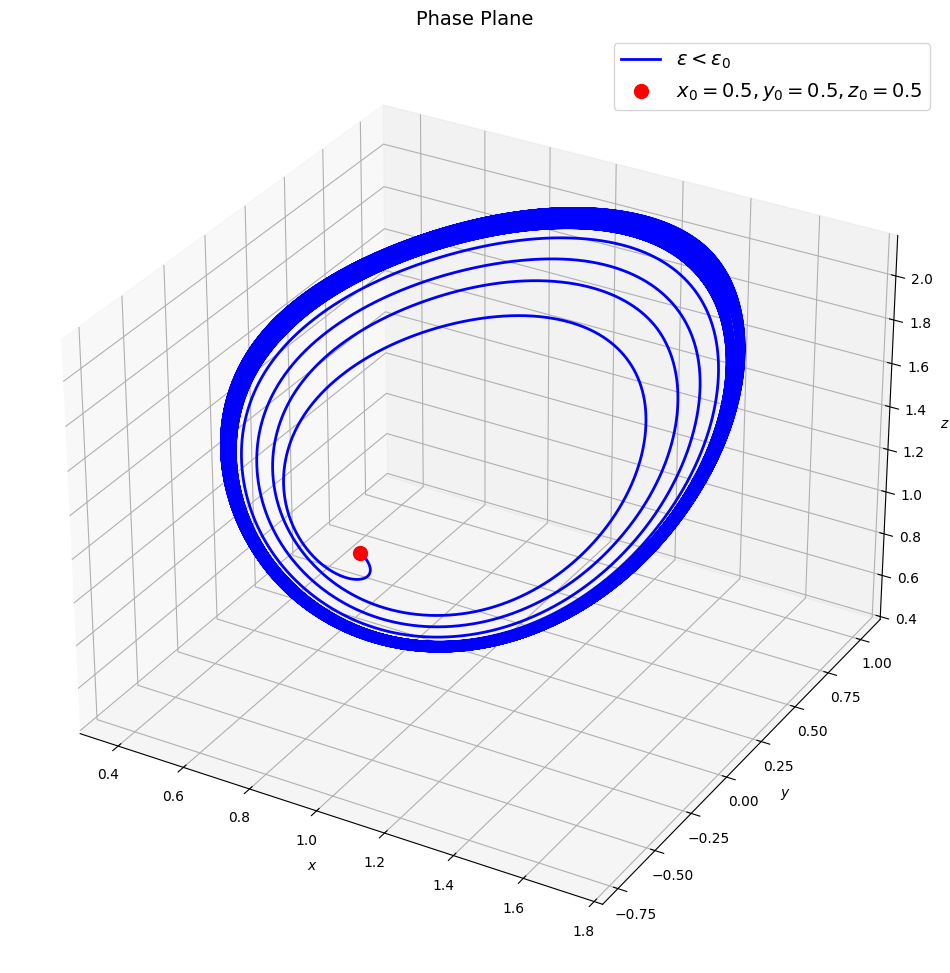

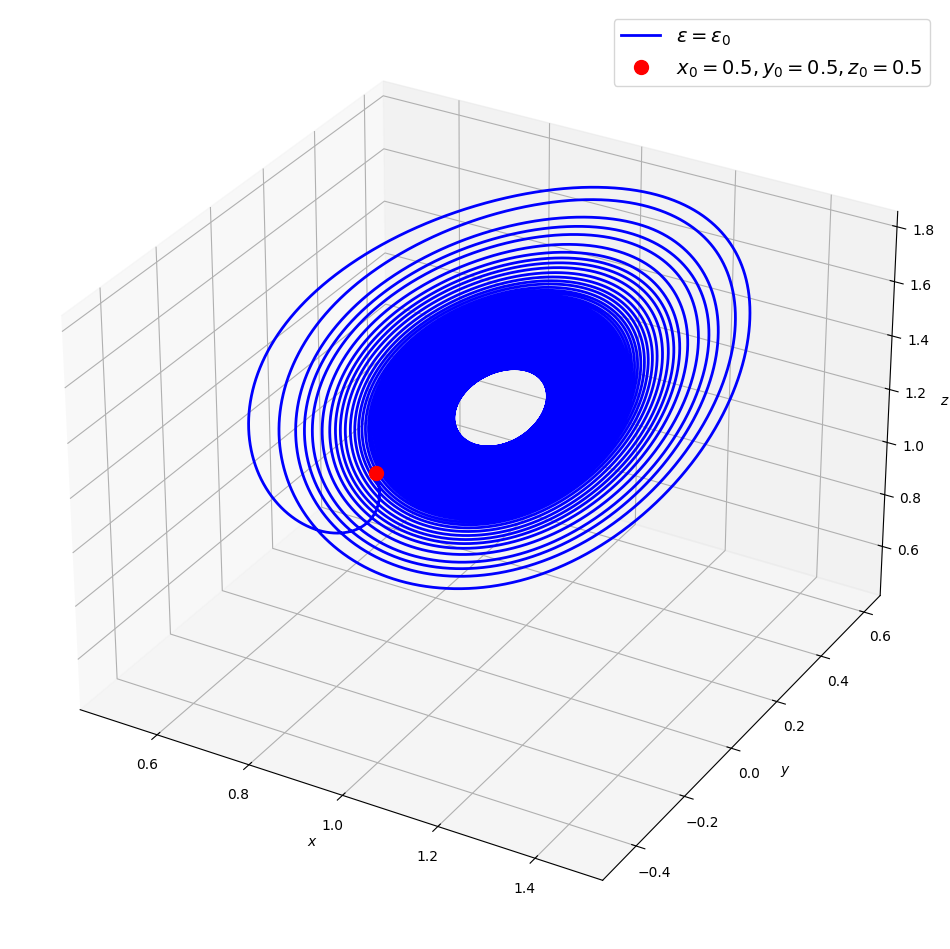

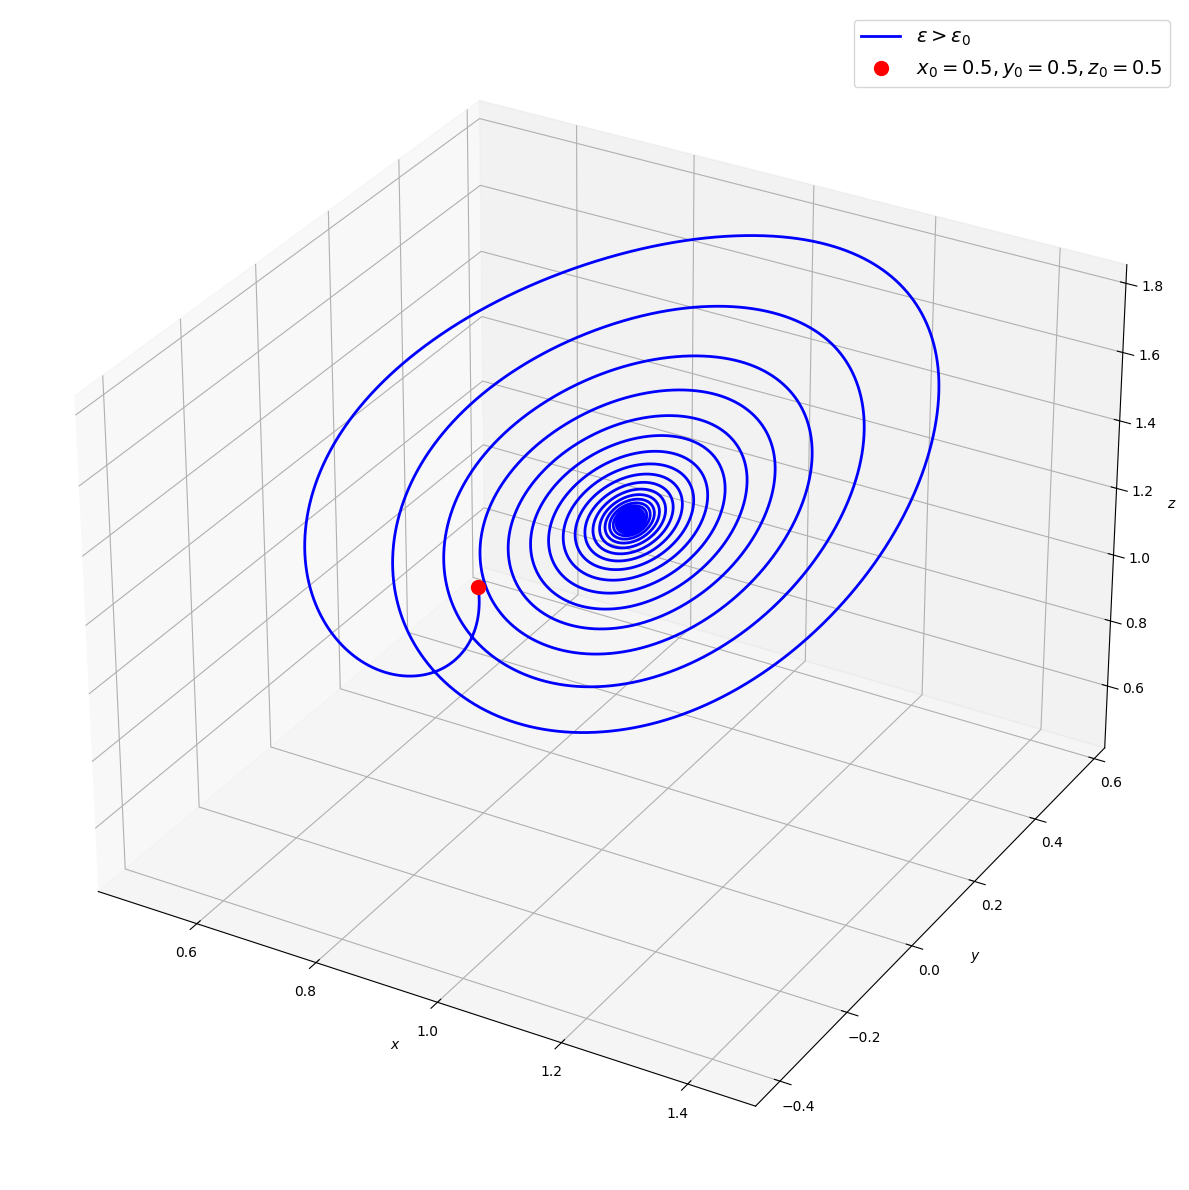

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

#Help for solving the IVP came from https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html
#Help for 3D plotting is from https://matplotlib.org/stable/gallery/mplot3d/2dcollections3d.html

# Define the nondimensionalized system for the centrifugal governor
def nondim_centrif_gov(t, w, alpha, beta, epsilon):
    x, y, z = w
    return [y, np.sin(x)*(z**2 * np.cos(x) - 1) - epsilon * y, alpha * (np.cos(x) - beta)]

#Define time interval using np.linspace
t = np.linspace(0, 1000, 1000000)

#Define alpha, beta and epsilon_0
alpha = 1
beta = 0.5
epsilon_0 = np.sqrt(2) / 2 #since  epsilon_0 = 2 * alpha * beta^{3/2}

###PLOT 1: epsilon < epsilon_0--------------------------------------------------

# Initial conditions are [x(0), y(0)], z(0)] = [1, 1, 1] with alpha = 1, beta = 0.5 and epsilon < epsilon_0
sol_1 = solve_ivp(nondim_centrif_gov, [0, 1000], [0.5, 0.5, 0.5], args=(alpha, beta, epsilon_0 - 0.1), t_eval=t)
x_1, y_1, z_1 = sol_1.y

#Initialize 3D figure and axis object
fig_1 = plt.figure(figsize=(12, 30))
ax_1 = fig_1.add_subplot(projection='3d')

# Plot the state trajectory
ax_1.plot(x_1, y_1, z_1, color='b', linewidth=2, label=f'$\epsilon < \epsilon_0$')

#Plot the initial condition
ax_1.scatter(0.5, 0.5, 0.5, color='r', s=100, label=f'$x_0=0.5, y_0=0.5, z_0=0.5$')

# Plot everything + make labels
ax_1.set_title('Phase Plane', fontsize=14)
ax_1.set_xlabel(r'$x$')
ax_1.set_ylabel(r'$y$')
ax_1.set_zlabel(r'$z$')
ax_1.tick_params(axis='both', which='major', labelsize=10)
ax_1.legend(fontsize=14)


###PLOT 2: epsilon = epsilon_0--------------------------------------------------

# Initial conditions are [x(0), y(0)], z(0)] = [1, 1, 1] with alpha = 1, beta = 0.5 and epsilon = epsilon_0
sol_2 = solve_ivp(nondim_centrif_gov, [0, 1000], [0.5, 0.5, 0.5], args=(alpha, beta, epsilon_0), t_eval=t)
x_2, y_2, z_2 = sol_2.y

#Initialize 3D figure and axis object
fig_2 = plt.figure(figsize=(12, 30))
ax_2 = fig_2.add_subplot(projection='3d')

# Plot the state trajectory
ax_2.plot(x_2, y_2, z_2, color='b', linewidth=2, label=f'$\epsilon = \epsilon_0$')

#Plot the initial condition
ax_2.scatter(0.5, 0.5, 0.5, color='r', s=100, label=f'$x_0=0.5, y_0=0.5, z_0=0.5$')

# Plot everything + make labels
ax_2.set_xlabel(r'$x$')
ax_2.set_ylabel(r'$y$')
ax_2.set_zlabel(r'$z$')
ax_2.tick_params(axis='both', which='major', labelsize=10)
ax_2.legend(fontsize=14)

###PLOT 3: epsilon > epsilon_0--------------------------------------------------

# Initial conditions are [x(0), y(0)], z(0)] = [1, 1, 1] with alpha = 1, beta = 0.5 and epsilon > epsilon_0
sol_3 = solve_ivp(nondim_centrif_gov, [0, 1000], [0.5, 0.5, 0.5], args=(alpha, beta, epsilon_0 + 0.1), t_eval=t)
x_3, y_3, z_3 = sol_3.y

#Initialize 3D figure and axis object
fig_3 = plt.figure(figsize=(12, 30))
ax_3 = fig_3.add_subplot(projection='3d')

# Plot the state trajectory
ax_3.plot(x_3, y_3, z_3, color='b', linewidth=2, label=f'$\epsilon > \epsilon_0$')

#Plot the initial condition
ax_3.scatter(0.5, 0.5, 0.5, color='r', s=100, label=f'$x_0=0.5, y_0=0.5, z_0=0.5$')

# Plot everything + make labels
ax_3.set_xlabel(r'$x$')
ax_3.set_ylabel(r'$y$')
ax_3.set_zlabel(r'$z$')
ax_3.tick_params(axis='both', which='major', labelsize=10)
ax_3.legend(fontsize=14)


plt.tight_layout()
plt.show()